# Análise estatística dos pagamentos da Saúde de Criciúma

**Pergunta:** Como o perfil das despesas e a execução orçamentária se associam ao intervalo entre o empenho e o pagamento na Saúde de Criciúma, e como esses padrões podem apoiar a programação dos desembolsos?

**Período:** pagamentos de 2023 a 2025. **Unidade de observação:** registro de pagamento. **Alvo:** `intervalo_empenho_pagamento_dias`.

Este notebook continua o `Unificacao_Saude.ipynb` e lê o CSV já produzido. Usa listas, `for`, `if` e bibliotecas presentes nas aulas: pandas, NumPy, SciPy, Matplotlib e statsmodels. Não altera os CSVs originais nem a base unificada.

Sequência: preparar 25 candidatas, calcular correlações, selecionar as 15 que atingem o limite, descrever o alvo, testar sua normalidade, experimentar as transformações das aulas e ajustar regressões exploratórias.

As correlações e os modelos descrevem o conjunto fornecido. O intervalo não equivale a atraso; empenhos estimativos podem prever pagamentos ao longo de vários meses.


## 1. Ler a base unificada

A leitura do CSV reconhece os valores monetários e o intervalo como números. Não é necessário calcular as datas novamente.


In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from scipy.special import inv_boxcox
import matplotlib.pyplot as plt
import statsmodels.api as sm

base = pd.read_csv("Base_unificada_Saude.csv")
alvo = "intervalo_empenho_pagamento_dias"

print("Registros:", len(base))
print("Colunas da base unificada:", len(base.columns))
base.head()


Registros: 26125
Colunas da base unificada: 40


,Nome da entidade,Ano de exercício,Número do empenho,Data do empenho,Descrição da função,Descrição da subfunção,Programa,Descrição do órgão,Descrição da unidade do empenho,Tipo de empenho,Categoria do empenho,Máscara do elemento,Elemento,Grupo do elemento,Modalidade de aplicação,Tipo de recurso,Descrição do recurso,Projeto/atividade,Valor do empenho,Número da despesa,Data do pagamento,Tipo de pagamento,Valor do pagamento R$,Valor orçado da despesa R$,Valor alterado da despesa R$,Valor atualizado da despesa R$,Empenhado atualizado da despesa R$,Liquidado atualizado da despesa R$,Saldo a liquidar da despesa R$,Anulações do pagamento da despesa R$,Valor pago atualizado da despesa R$,Saldo a pagar da despesa - empenhado R$,Saldo a pagar da despesa - liquidado R$,% Empenhado sobre orçado,% Empenhado sobre orçado atualizado,% Liquidado sobre orçado,% Liquidado sobre orçado atualizado,% Pago sobre orçado,% Pago sobre orçado atualizado,intervalo_empenho_pagamento_dias
0,PREFEITURA MUNICIPAL DE CRICIUMA,2023,7295,2023-11-23,Saúde,Tecnologia da Informatização,SAUDE PARA TODOS,GABINETE DO PREFEITO,Gabinete do Prefeito,Ordinário,PROCESSO,44905235000000,Equipamentos de Processamento de Dados,INVESTIMENTOS,Aplicações Diretas,vinculado,Transferências de Estado referentes a Convênios e Instrumentos Congêneres vinculados à Saúde/ Superávit Exercício Anterior,Aquisição de equipamentos e materiais permanentes de TI,58514.00,229,2024-02-28,Débito em conta,36714.00,0,521444.4,521444.4,317314.0,21800.0,295514.0,0.0,261.6,317052.4,21538.4,0.0,60.85,0.0,4.18,0.0,199328.9,97
1,PREFEITURA MUNICIPAL DE CRICIUMA,2023,7295,2023-11-23,Saúde,Tecnologia da Informatização,SAUDE PARA TODOS,GABINETE DO PREFEITO,Gabinete do Prefeito,Ordinário,PROCESSO,44905235000000,Equipamentos de Processamento de Dados,INVESTIMENTOS,Aplicações Diretas,vinculado,Transferências de Estado referentes a Convênios e Instrumentos Congêneres vinculados à Saúde/ Superávit Exercício Anterior,Aquisição de equipamentos e materiais permanentes de TI,58514.00,229,2024-02-15,Débito em conta,21800.00,0,521444.4,521444.4,317314.0,21800.0,295514.0,0.0,261.6,317052.4,21538.4,0.0,60.85,0.0,4.18,0.0,199328.9,84
2,PREFEITURA MUNICIPAL DE CRICIUMA,2023,7279,2023-11-23,Saúde,Tecnologia da Informatização,SAUDE PARA TODOS,GABINETE DO PREFEITO,Gabinete do Prefeito,Ordinário,PROCESSO,44905235000000,Equipamentos de Processamento de Dados,INVESTIMENTOS,Aplicações Diretas,Ordinário,Receitas de Impostos e de Transferência de Impostos - Saúde,Aquisição de equipamentos e materiais permanentes de TI,10900.00,229,2024-02-28,Débito em conta,10900.00,0,521444.4,521444.4,317314.0,21800.0,295514.0,0.0,261.6,317052.4,21538.4,0.0,60.85,0.0,4.18,0.0,199328.9,97
3,PREFEITURA MUNICIPAL DE CRICIUMA,2023,7278,2023-11-23,Saúde,Tecnologia da Informatização,SAUDE PARA TODOS,GABINETE DO PREFEITO,Gabinete do Prefeito,Ordinário,PROCESSO,44905235000000,Equipamentos de Processamento de Dados,INVESTIMENTOS,Aplicações Diretas,Ordinário,Receitas de Impostos e de Transferência de Impostos - Saúde,Aquisição de equipamentos e materiais permanentes de TI,73902.43,229,2024-02-28,Débito em conta,73902.43,0,521444.4,521444.4,317314.0,21800.0,295514.0,0.0,261.6,317052.4,21538.4,0.0,60.85,0.0,4.18,0.0,199328.9,97
4,PREFEITURA MUNICIPAL DE CRICIUMA,2023,7277,2023-11-23,Saúde,Tecnologia da Informatização,SAUDE PARA TODOS,GABINETE DO PREFEITO,Gabinete do Prefeito,Ordinário,PROCESSO,44905235000000,Equipamentos de Processamento de Dados,INVESTIMENTOS,Aplicações Diretas,vinculado,Transferências de Estado referentes a Convênios e Instrumentos Congêneres vinculados à Saúde/ Superávit Exercício Anterior,Aquisição de equipamentos e materiais permanentes de TI,173997.57,229,2024-02-28,Débito em conta,173997.57,0,521444.4,521444.4,317314.0,21800.0,295514.0,0.0,261.6,317052.4,21538.4,0.0,60.85,0.0,4.18,0.0,199328.9,97


## 2. Representar as características como 0 ou 1

As variáveis dummy aparecem na Aula 10, slides 24 a 26. Cada coluna responde a uma pergunta simples: 1 significa que a característica está presente; 0 significa que não está.

Não transformaremos códigos de despesa em uma escala numérica. O código contábil abaixo é usado somente para identificar a categoria de serviços médicos, odontológicos e laboratoriais. Uma única categoria pode ter mais de uma classificação na prefeitura; aqui o indicador é especificamente a máscara `33903950000000`, usada na triagem.

Para os empenhos, criaremos somente o indicador de **estimativo**. Não criaremos também o de ordinário, que seria seu complemento e repetiria a mesma informação.


In [2]:
empenho_estimativo = []
categoria_processo = []
categoria_diaria = []
categoria_folha = []
atencao_basica = []
assistencia_hospitalar_ambulatorial = []
servicos_medicos_odontologicos_laboratoriais = []

for i in base.index:
    if base["Tipo de empenho"][i] == "Estimativo":
        empenho_estimativo += [1]
    else:
        empenho_estimativo += [0]

    if base["Categoria do empenho"][i] == "PROCESSO":
        categoria_processo += [1]
    else:
        categoria_processo += [0]

    if base["Categoria do empenho"][i] == "DIARIA":
        categoria_diaria += [1]
    else:
        categoria_diaria += [0]

    if base["Categoria do empenho"][i] == "FOLHA":
        categoria_folha += [1]
    else:
        categoria_folha += [0]

    if base["Descrição da subfunção"][i] == "Atenção Básica":
        atencao_basica += [1]
    else:
        atencao_basica += [0]

    if base["Descrição da subfunção"][i] == "Assistência Hospitalar e Ambulatorial":
        assistencia_hospitalar_ambulatorial += [1]
    else:
        assistencia_hospitalar_ambulatorial += [0]

    if base["Máscara do elemento"][i] == 33903950000000:
        servicos_medicos_odontologicos_laboratoriais += [1]
    else:
        servicos_medicos_odontologicos_laboratoriais += [0]

base["empenho_estimativo"] = empenho_estimativo
base["categoria_processo"] = categoria_processo
base["categoria_diaria"] = categoria_diaria
base["categoria_folha"] = categoria_folha
base["atencao_basica"] = atencao_basica
base["assistencia_hospitalar_ambulatorial"] = assistencia_hospitalar_ambulatorial
base["servicos_medicos_odontologicos_laboratoriais"] = servicos_medicos_odontologicos_laboratoriais


## 3. Escolher as 25 variáveis candidatas

São 16 medidas orçamentárias, 7 características representadas por 0/1 e 2 valores monetários. São hipóteses de associação a verificar, não 25 relações previamente comprovadas.

As medidas de orçamento correspondem à dotação, compartilhada por vários pagamentos. Elas não podem ser somadas nas linhas para obter o orçamento municipal. Há relações contábeis entre algumas explicativas, portanto correlação com o alvo não garante que todas devam entrar juntas em uma regressão.


In [3]:
variaveis_candidatas = [
    "Valor orçado da despesa R$",
    "Valor alterado da despesa R$",
    "Valor atualizado da despesa R$",
    "Empenhado atualizado da despesa R$",
    "Liquidado atualizado da despesa R$",
    "Saldo a liquidar da despesa R$",
    "Anulações do pagamento da despesa R$",
    "Valor pago atualizado da despesa R$",
    "Saldo a pagar da despesa - empenhado R$",
    "Saldo a pagar da despesa - liquidado R$",
    "% Empenhado sobre orçado",
    "% Empenhado sobre orçado atualizado",
    "% Liquidado sobre orçado",
    "% Liquidado sobre orçado atualizado",
    "% Pago sobre orçado",
    "% Pago sobre orçado atualizado",
    "empenho_estimativo",
    "categoria_processo",
    "categoria_diaria",
    "categoria_folha",
    "atencao_basica",
    "assistencia_hospitalar_ambulatorial",
    "servicos_medicos_odontologicos_laboratoriais",
    "Valor do empenho",
    "Valor do pagamento R$"
]

base_analise = base[[alvo] + variaveis_candidatas]

print("Registros da análise:", len(base_analise))
print("Variáveis candidatas:", len(variaveis_candidatas))


Registros da análise: 26125
Variáveis candidatas: 25


## 4. Calcular as correlações e aplicar o limite do trabalho

O comando `corr()` foi usado nos exercícios de 25/08. O coeficiente de Pearson varia de -1 a 1. O requisito dos slides é **r menor que -0,3 ou maior que 0,3**. O limite é estrito: exatamente 0,3 ou -0,3 não seria suficiente.

Nas variáveis 0/1, o sinal compara a presença da característica com os demais registros. Não significa que uma categoria cause aumento ou redução do intervalo. A seleção desta pergunta foi exploratória, depois de testar outras alternativas; estes resultados não são uma confirmação em dados novos.


In [4]:
matriz_correlacao = base_analise.corr()
variaveis_selecionadas = []
linhas_correlacoes = []

for variavel in variaveis_candidatas:
    r = matriz_correlacao[alvo][variavel]
    if r < -0.3 or r > 0.3:
        variaveis_selecionadas += [variavel]
        atende = "Sim"
    else:
        atende = "Não"

    linhas_correlacoes += [[variavel, r, atende]]

tabela_correlacoes = pd.DataFrame(
    linhas_correlacoes,
    columns=["Variável", "Correlação com o alvo", "Atinge o limite"]
)

print("Quantidade acima do limite:", len(variaveis_selecionadas))
if len(variaveis_selecionadas) >= 15:
    print("O requisito de pelo menos 15 correlações foi atingido.")
else:
    print("Será necessário buscar mais 10 candidatas e repetir a verificação.")

tabela_correlacoes


Quantidade acima do limite: 15
O requisito de pelo menos 15 correlações foi atingido.


,Variável,Correlação com o alvo,Atinge o limite
0,Valor orçado da despesa R$,0.396675,Sim
1,Valor alterado da despesa R$,0.059245,Não
2,Valor atualizado da despesa R$,0.407049,Sim
3,Empenhado atualizado da despesa R$,0.342433,Sim
4,Liquidado atualizado da despesa R$,0.327130,Sim
5,Saldo a liquidar da despesa R$,0.421699,Sim
6,Anulações do pagamento da despesa R$,-0.048778,Não
7,Valor pago atualizado da despesa R$,0.325682,Sim
8,Saldo a pagar da despesa - empenhado R$,0.413365,Sim
9,Saldo a pagar da despesa - liquidado R$,0.339551,Sim


## 5. Separar o alvo e as variáveis selecionadas

O resultado é a base estatística com **26.125 registros e 16 colunas**: o alvo original e as 15 explicativas selecionadas. A base unificada de 40 colunas continua preservada no seu CSV.

Esta seleção atende ao critério de correlação do trabalho. Não obriga a usar todas as explicativas no mesmo modelo: algumas medidas orçamentárias são fortemente relacionadas entre si.


In [5]:
base_selecionada = base_analise[[alvo] + variaveis_selecionadas]

print("Registros da base selecionada:", len(base_selecionada))
print("Colunas, incluindo o alvo:", len(base_selecionada.columns))
base_selecionada.head()


Registros da base selecionada: 26125
Colunas, incluindo o alvo: 16


,intervalo_empenho_pagamento_dias,Valor orçado da despesa R$,Valor atualizado da despesa R$,Empenhado atualizado da despesa R$,Liquidado atualizado da despesa R$,Saldo a liquidar da despesa R$,Valor pago atualizado da despesa R$,Saldo a pagar da despesa - empenhado R$,Saldo a pagar da despesa - liquidado R$,empenho_estimativo,categoria_processo,categoria_diaria,categoria_folha,atencao_basica,assistencia_hospitalar_ambulatorial,servicos_medicos_odontologicos_laboratoriais
0,97,0,521444.4,317314.0,21800.0,295514.0,261.6,317052.4,21538.4,0,1,0,0,0,0,0
1,84,0,521444.4,317314.0,21800.0,295514.0,261.6,317052.4,21538.4,0,1,0,0,0,0,0
2,97,0,521444.4,317314.0,21800.0,295514.0,261.6,317052.4,21538.4,0,1,0,0,0,0,0
3,97,0,521444.4,317314.0,21800.0,295514.0,261.6,317052.4,21538.4,0,1,0,0,0,0,0
4,97,0,521444.4,317314.0,21800.0,295514.0,261.6,317052.4,21538.4,0,1,0,0,0,0,0


## 6. Medidas descritivas do intervalo

Usaremos os cálculos de média, mediana, moda, quartis, variância, desvio padrão e amplitude das Aulas 2 e dos exercícios de agosto. A variância e o desvio padrão abaixo usam a convenção populacional de `np.var` e `np.std`, igual à utilizada nos exercícios, descrevendo o conjunto disponível.


In [6]:
intervalos = np.array(base[alvo])

media = intervalos.mean()
mediana = np.median(intervalos)
moda = stats.mode(intervalos)[0]
q1 = np.percentile(intervalos, 25)
q3 = np.percentile(intervalos, 75)
variancia = np.var(intervalos)
desvio_padrao = np.std(intervalos)
amplitude = intervalos.max() - intervalos.min()

linhas_descritivas = [
    ["Quantidade", len(intervalos)],
    ["Média (dias)", media],
    ["Mediana (dias)", mediana],
    ["Moda (dias)", moda],
    ["Primeiro quartil (dias)", q1],
    ["Terceiro quartil (dias)", q3],
    ["Mínimo (dias)", intervalos.min()],
    ["Máximo (dias)", intervalos.max()],
    ["Amplitude (dias)", amplitude],
    ["Variância populacional (dias²)", variancia],
    ["Desvio padrão populacional (dias)", desvio_padrao]
]

tabela_descritiva = pd.DataFrame(linhas_descritivas, columns=["Medida", "Valor"])
tabela_descritiva


,Medida,Valor
0,Quantidade,26125.000000
1,Média (dias),75.838545
2,Mediana (dias),34.000000
3,Moda (dias),1.000000
4,Primeiro quartil (dias),7.000000
5,Terceiro quartil (dias),118.000000
6,Mínimo (dias),0.000000
7,Máximo (dias),504.000000
8,Amplitude (dias),504.000000
9,Variância populacional (dias²),8933.891712


## 7. Visualizar os dados

O boxplot e o gráfico de dispersão foram usados nas aulas. No gráfico com indicador 0/1, os pontos se sobrepõem porque muitos pagamentos compartilham a mesma categoria e o mesmo intervalo.


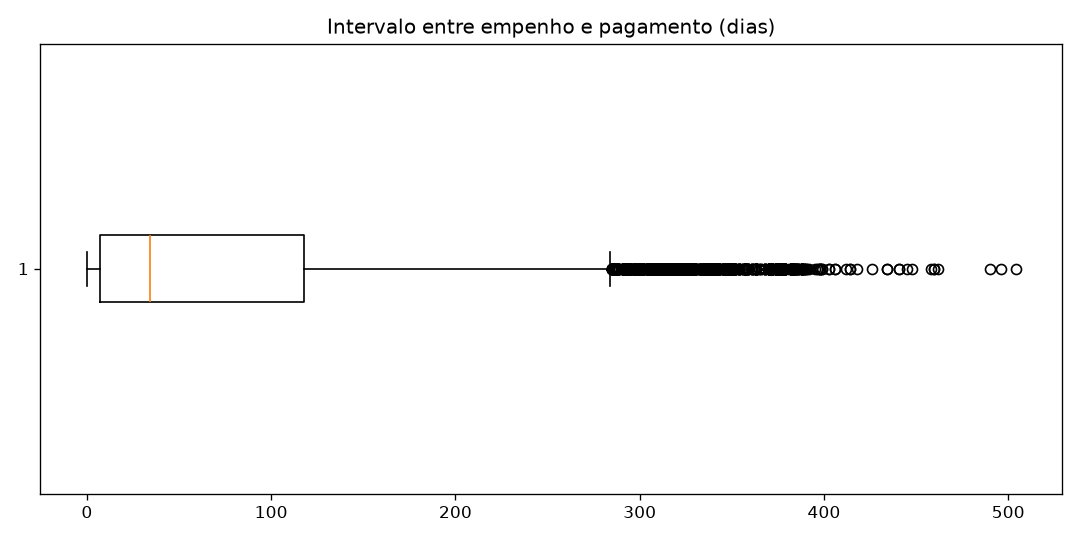

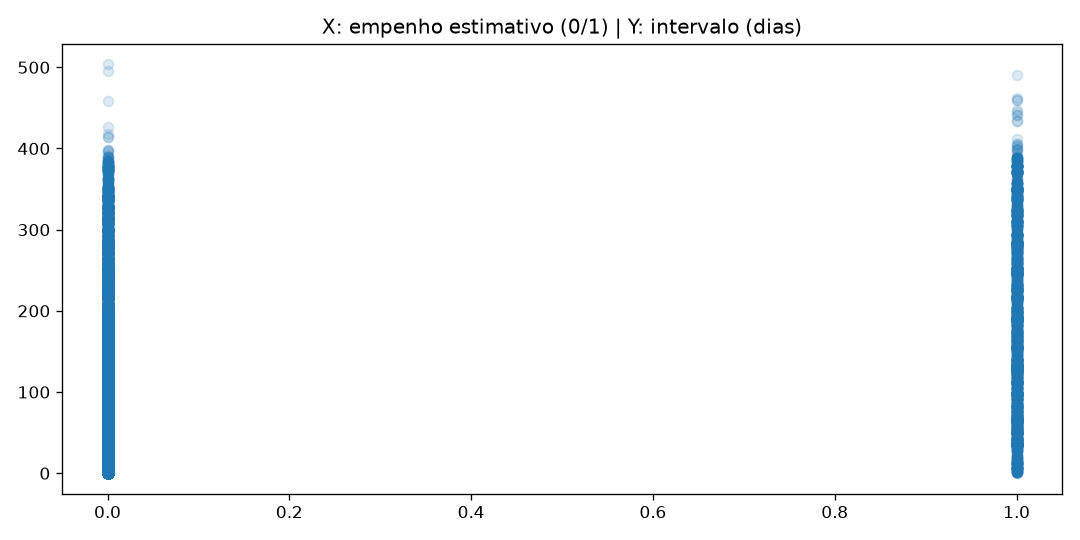

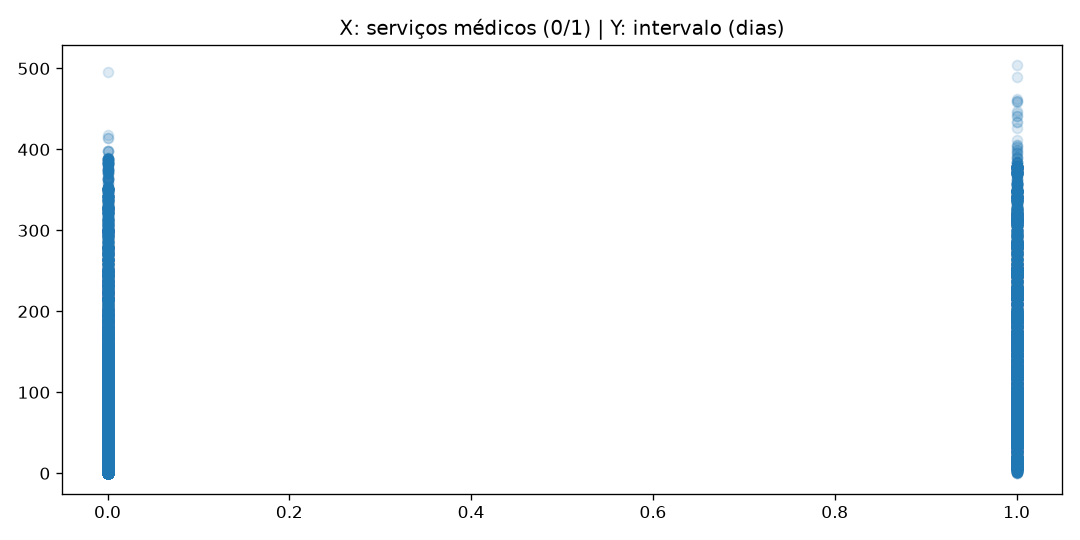

In [7]:
plt.boxplot(intervalos, orientation="horizontal")
plt.title("Intervalo entre empenho e pagamento (dias)")
plt.show()

plt.scatter(base["empenho_estimativo"], intervalos, alpha=0.15)
plt.title("X: empenho estimativo (0/1) | Y: intervalo (dias)")
plt.show()

plt.scatter(base["servicos_medicos_odontologicos_laboratoriais"], intervalos, alpha=0.15)
plt.title("X: serviços médicos (0/1) | Y: intervalo (dias)")
plt.show()


## 8. Testar a normalidade do alvo original

O checkpoint da Aula 8 solicita o Shapiro-Wilk. Nos exercícios de setembro, usamos `stats.shapiro` e comparamos o p-valor com 0,05. Um resultado maior que 0,05 significa que o teste não rejeitou a normalidade, não que a tenha provado.

**Limitações:** são 26.125 registros. A documentação do SciPy informa que, para mais de 5.000 observações, o p-valor pode ser impreciso. Além disso, vários pagamentos compartilham empenhos e dotações; os registros não representam uma amostra de observações todas independentes. Registraremos o teste como exercício diagnóstico, sem usar seu p-valor como certificação da distribuição.

Fonte técnica: [documentação do Shapiro-Wilk no SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.shapiro.html).


In [8]:
teste_original = stats.shapiro(intervalos)

print("Estatística W:", teste_original[0])
print(f"p-valor aproximado: {teste_original[1]:.3e}")
if teste_original[1] > 0.05:
    print("O teste não rejeitou a normalidade, com as ressalvas descritas.")
else:
    print("O diagnóstico aponta afastamento da normalidade, com as ressalvas descritas.")


Estatística W: 0.7788179487117616
p-valor aproximado: 8.591e-102
O diagnóstico aponta afastamento da normalidade, com as ressalvas descritas.


## 9. Experimentar os limites para os outliers

Na Aula 7, slides 35 a 39, e no exercício de 22/09, foi apresentada a substituição dos valores extremos pelo limite de 1,5 amplitude interquartil.

Faremos o experimento em **outra lista**, preservando o intervalo original. Valores altos podem ser pagamentos previstos para vários meses depois do empenho, e não erros. Por isso, esse tratamento não será adotado automaticamente na base final.


Limite inferior: -159.5
Limite superior: 284.5
Valores modificados somente no experimento: 1396
p-valor aproximado após os limites: 2.494e-101


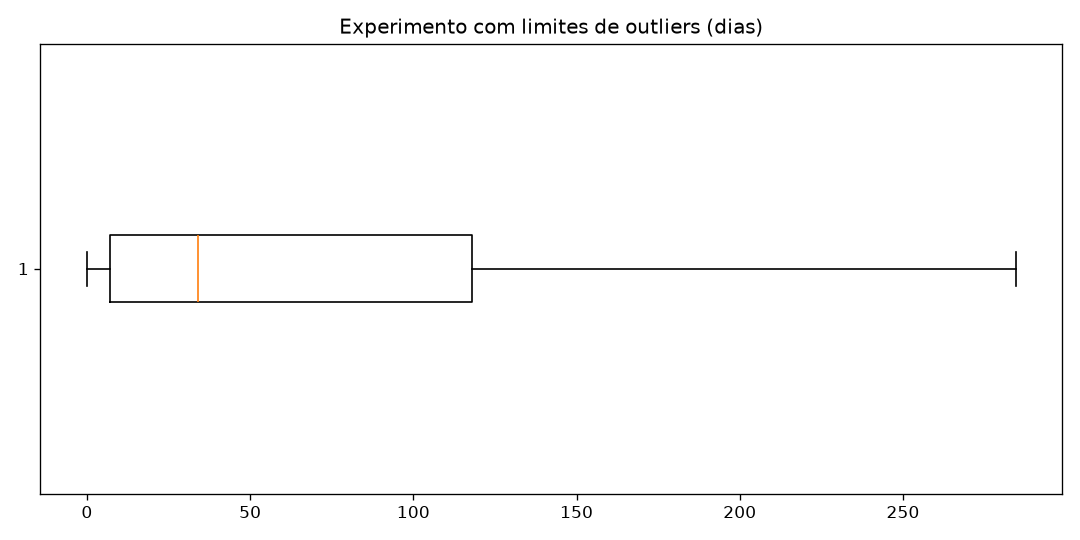

In [9]:
amplitude_interquartil = q3 - q1
limite_inferior = q1 - 1.5 * amplitude_interquartil
limite_superior = q3 + 1.5 * amplitude_interquartil

intervalos_limitados = []
quantidade_limitada = 0

for valor in intervalos:
    if valor < limite_inferior:
        intervalos_limitados += [limite_inferior]
        quantidade_limitada += 1
    elif valor > limite_superior:
        intervalos_limitados += [limite_superior]
        quantidade_limitada += 1
    else:
        intervalos_limitados += [valor]

intervalos_limitados = np.array(intervalos_limitados)
teste_limites = stats.shapiro(intervalos_limitados)

print("Limite inferior:", limite_inferior)
print("Limite superior:", limite_superior)
print("Valores modificados somente no experimento:", quantidade_limitada)
print(f"p-valor aproximado após os limites: {teste_limites[1]:.3e}")

plt.boxplot(intervalos_limitados, orientation="horizontal")
plt.title("Experimento com limites de outliers (dias)")
plt.show()


## 10. Experimentar raiz quadrada e Box-Cox

A raiz quadrada foi explicada na Aula 7. A transformação Box-Cox foi explicada na mesma aula e usada no exercício de 22/09, inclusive com a função inversa.

Há intervalos iguais a zero e Box-Cox exige valores positivos. Somaremos **1** antes de aplicá-la. Ao inverter, subtrairemos **1**. Essa constante permite aplicar a técnica sem excluir os pagamentos no mesmo dia. Ela não muda o alvo original da base.

Testaremos Box-Cox sobre o alvo original e, separadamente, sobre a versão limitada. Não procuraremos valores de transformação até obter um p-valor desejado.

Fonte técnica: [documentação do Box-Cox no SciPy](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.boxcox.html).


In [10]:
intervalos_raiz = intervalos ** 0.5
teste_raiz = stats.shapiro(intervalos_raiz)

intervalos_boxcox, lambda_original = stats.boxcox(intervalos + 1)
teste_boxcox = stats.shapiro(intervalos_boxcox)

intervalos_boxcox_limites, lambda_limites = stats.boxcox(intervalos_limitados + 1)
teste_boxcox_limites = stats.shapiro(intervalos_boxcox_limites)

linhas_normalidade = [
    ["Original", teste_original[0], teste_original[1]],
    ["Com limites de outliers", teste_limites[0], teste_limites[1]],
    ["Raiz quadrada", teste_raiz[0], teste_raiz[1]],
    ["Box-Cox do original + 1", teste_boxcox[0], teste_boxcox[1]],
    ["Box-Cox após limites + 1", teste_boxcox_limites[0], teste_boxcox_limites[1]]
]

tabela_normalidade = pd.DataFrame(
    linhas_normalidade,
    columns=["Versão do alvo", "Estatística W", "p-valor aproximado"]
)

print("Lambda Box-Cox do original:", lambda_original)
print("Lambda Box-Cox após limites:", lambda_limites)
print("Os p-valores de todas as versões são aproximados para este tamanho de base.")
tabela_normalidade


Lambda Box-Cox do original: 0.09908642247154485
Lambda Box-Cox após limites: 0.11003198698971063
Os p-valores de todas as versões são aproximados para este tamanho de base.


,Versão do alvo,Estatística W,p-valor aproximado
0,Original,0.778818,8.591347e-102
1,Com limites de outliers,0.782800,2.493511e-101
2,Raiz quadrada,0.920616,2.276807e-77
3,Box-Cox do original + 1,0.959613,3.956803e-63
4,Box-Cox após limites + 1,0.951295,6.304720e-67


Primeiros intervalos originais: [97 84 97 97 97]
Intervalos recuperados: [97. 84. 97. 97. 97.]


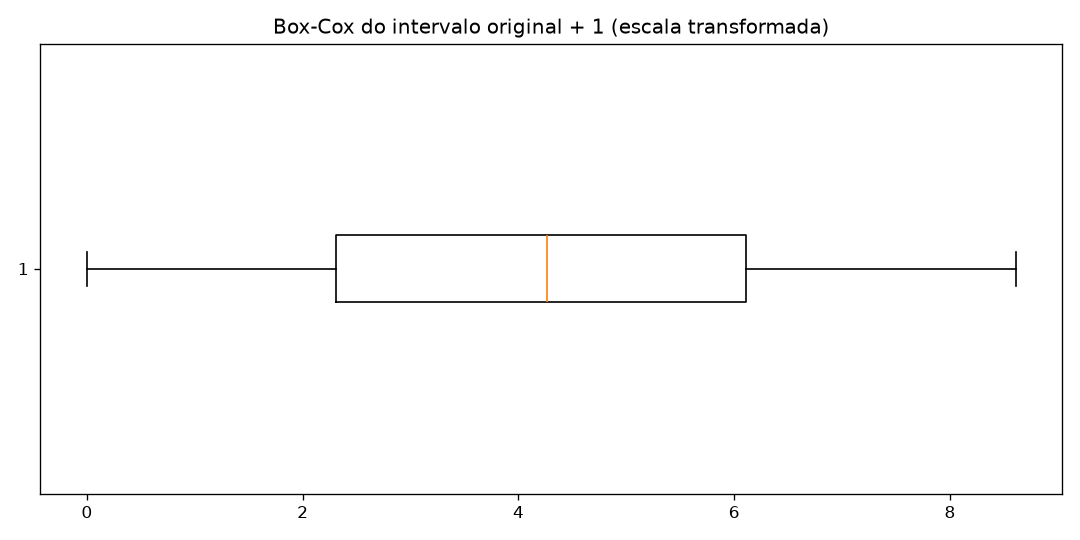

In [11]:
# A inversa recupera os intervalos originais, salvo arredondamentos numéricos.
intervalos_recuperados = inv_boxcox(intervalos_boxcox, lambda_original) - 1
print("Primeiros intervalos originais:", intervalos[0:5])
print("Intervalos recuperados:", intervalos_recuperados[0:5])

plt.boxplot(intervalos_boxcox, orientation="horizontal")
plt.title("Box-Cox do intervalo original + 1 (escala transformada)")
plt.show()


### Resultado das tentativas

O Box-Cox aproximou a forma da distribuição da normal mais do que os demais experimentos, pelo aumento de W. Entretanto, nenhuma das versões apresentou p-valor acima de 0,05 no diagnóstico realizado. Não afirmamos que a normalização foi obtida. O alvo representa dias inteiros, inclui zeros e reúne diferentes perfis de despesas; não há garantia de que uma transformação resulte em distribuição normal.

As 15 correlações foram selecionadas com o **alvo original em dias**. Não são automaticamente as correlações do alvo transformado. A base estatística final manterá o intervalo original, e os experimentos ficarão documentados para discussão com o professor.


## 11. Regressão linear simples e múltipla: exercício da Aula 10

A Aula 10 apresenta regressões lineares com mínimos quadrados ordinários (OLS) e a biblioteca statsmodels. Aqui vamos reproduzir a ideia com poucos indicadores, sem colocar as medidas orçamentárias relacionadas todas no mesmo modelo.

No modelo simples, a explicativa é o indicador de empenho estimativo. No múltiplo, acrescentamos a categoria Processo e a subfunção Assistência Hospitalar e Ambulatorial. A constante é uma coluna preenchida com 1, que permite estimar o termo inicial da equação.

Os modelos usam o intervalo **original em dias** e todos os registros, somente para descrever o ajuste histórico. A normalidade do alvo isoladamente não é um requisito da regressão OLS; ela não substitui a análise dos resíduos. Os registros compartilham empenhos e dotações, e este exercício não corrige essa dependência. Portanto, os erros padrão e p-valores convencionais do resumo não justificam afirmar confiança preditiva ou causalidade. Não haverá previsão para gastos futuros.


In [12]:
x_simples = pd.DataFrame(base_analise[["empenho_estimativo"]])
x_simples["constante"] = 1

modelo_simples = sm.OLS(base_analise[alvo], x_simples).fit()
print(modelo_simples.summary())


                                   OLS Regression Results                                   
Dep. Variable:     intervalo_empenho_pagamento_dias   R-squared:                       0.144
Model:                                          OLS   Adj. R-squared:                  0.144
Method:                               Least Squares   F-statistic:                     4395.
Date:                              Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                                      15:15:57   Log-Likelihood:            -1.5388e+05
No. Observations:                             26125   AIC:                         3.078e+05
Df Residuals:                                 26123   BIC:                         3.078e+05
Df Model:                                         1                                         
Covariance Type:                          nonrobust                                         
                         coef    std err          t      P>|t|      [0

In [13]:
x_multiplo = pd.DataFrame(base_analise[[
    "empenho_estimativo",
    "categoria_processo",
    "assistencia_hospitalar_ambulatorial"
]])
x_multiplo["constante"] = 1

modelo_multiplo = sm.OLS(base_analise[alvo], x_multiplo).fit()
print(modelo_multiplo.summary())

erros_simples = np.array(base_analise[alvo] - modelo_simples.fittedvalues)
erros_multiplos = np.array(base_analise[alvo] - modelo_multiplo.fittedvalues)

rmse_simples = ((erros_simples ** 2).mean()) ** 0.5
rmse_multiplo = ((erros_multiplos ** 2).mean()) ** 0.5

linhas_modelos = [
    ["Linear simples", modelo_simples.rsquared, rmse_simples],
    ["Linear múltipla", modelo_multiplo.rsquared, rmse_multiplo]
]

tabela_modelos = pd.DataFrame(
    linhas_modelos,
    columns=["Modelo", "R² no conjunto usado para ajustar", "RMSE no ajuste (dias)"]
)
tabela_modelos


                                   OLS Regression Results                                   
Dep. Variable:     intervalo_empenho_pagamento_dias   R-squared:                       0.359
Model:                                          OLS   Adj. R-squared:                  0.359
Method:                               Least Squares   F-statistic:                     4883.
Date:                              Sat, 31 Oct 2026   Prob (F-statistic):               0.00
Time:                                      15:15:57   Log-Likelihood:            -1.5009e+05
No. Observations:                             26125   AIC:                         3.002e+05
Df Residuals:                                 26121   BIC:                         3.002e+05
Df Model:                                         3                                         
Covariance Type:                          nonrobust                                         
                                          coef    std err          t  

,Modelo,R² no conjunto usado para ajustar,RMSE no ajuste (dias)
0,Linear simples,0.144022,87.448340
1,Linear múltipla,0.359308,75.656266


## 12. Comparar os tipos de empenho e responder à pergunta

Vamos calcular média e mediana do intervalo para cada tipo com listas e um `for`. Cada registro de pagamento tem o mesmo peso nesta comparação; não estamos ponderando pelo valor pago.


In [14]:
linhas_tipos = []

for tipo in ["Ordinário", "Estimativo"]:
    valores_tipo = []
    for i in base.index:
        if base["Tipo de empenho"][i] == tipo:
            valores_tipo += [base[alvo][i]]

    valores_tipo = np.array(valores_tipo)
    linhas_tipos += [[tipo, len(valores_tipo), valores_tipo.mean(), np.median(valores_tipo)]]

tabela_tipos = pd.DataFrame(
    linhas_tipos,
    columns=["Tipo de empenho", "Pagamentos", "Média do intervalo (dias)", "Mediana (dias)"]
)
tabela_tipos


,Tipo de empenho,Pagamentos,Média do intervalo (dias),Mediana (dias)
0,Ordinário,23294,63.333562,25.0
1,Estimativo,2831,178.731897,168.0


### Conclusão e uso para planejamento

No conjunto analisado, o perfil da despesa apresenta associação com o intervalo entre empenho e pagamento. Os empenhos estimativos, a categoria Processo e a subfunção hospitalar e ambulatorial têm correlação positiva com o intervalo; as categorias Diária e Folha e a subfunção Atenção Básica têm correlação negativa.

Isso pode apoiar a separação de calendários financeiros por perfil de despesa e o acompanhamento de desembolsos recorrentes. Intervalos longos podem refletir a própria forma de contratação e previsão anual. Não é possível concluir que sejam atrasos ou problemas de gestão sem datas de vencimento e contexto contratual.

**Limites da entrega:** os pagamentos realizados não incluem os ainda pendentes; a base fornecida não foi comprovada como toda a despesa da Saúde; os valores de orçamento vêm da exportação disponível, e não do histórico conhecido em cada data. A seleção de correlações é exploratória e há explicativas relacionadas entre si. As regressões são exercícios descritivos, sem validação em dados novos. A normalidade não foi atingida pelas tentativas realizadas.

### Conferência dos requisitos dos materiais enviados

- Aula 5, slide 9: base com pelo menos 20 mil linhas, alvo definido, 25 candidatas e pelo menos 15 correlações fora de [-0,3; 0,3].
- Aula 8, slide 4: teste de Shapiro-Wilk e tentativas de transformação da Aula 7, com resultados registrados.
- Aula 10: demonstração das regressões simples e múltipla, usando indicadores binários.

A aprovação da pergunta, a análise dos resultados não normais e eventuais orientações posteriores dependem do professor. Não foram fornecidos outros checklists de entrega final ou feedbacks específicos do grupo.
